# Tarea 5. Ejemplo de perceptrón en Python

**Materia:** Inteligencia Artificial
**Profesor:** José Mario Ríos Félix
**Horario:** 6:00 a 7:00 p. m.
**Alumno:** Daniel Jimenez Duarte
**No. de control:** 23170198

Se entrena un perceptrón con scikit-learn para separar dos grupos de puntos, se comparan varias funciones de activación y se incluye el ejemplo de neurona lineal visto en clase.

## 1. Perceptrón

El perceptrón es el modelo más simple de neurona artificial y sirve para clasificar. Funciona así:

1. Multiplica cada entrada por su **peso**.
2. Suma todo y le agrega un **sesgo** (*bias*).
3. Aplica una **función escalón**: si el resultado es mayor o igual a 0 responde clase 1, si no, clase 0.

Durante el entrenamiento recorre los datos varias veces (épocas) y corrige los pesos cada vez que se equivoca.

Referencia: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import Perceptron

# Genera 100 puntos en 2 grupos que se pueden separar con una recta
X, Y = make_blobs(n_samples=100, centers=2, n_features=2, cluster_std=1.0, random_state=42)

print(f"Puntos: {len(X)}")
print(f"Características por punto: {X.shape[1]}")
print(f"Clase 0: {np.sum(Y == 0)}    Clase 1: {np.sum(Y == 1)}")

Puntos: 100
Características por punto: 2
Clase 0: 50    Clase 1: 50


In [3]:
# Crea y entrena el perceptrón
clasificador = Perceptron(tol=1e-3, random_state=0)
clasificador.fit(X, Y)

# coef_ son los pesos e intercept_ es el sesgo
w1, w2 = clasificador.coef_[0]
b = clasificador.intercept_[0]

print(f"Peso 1 (w1): {w1:.4f}")
print(f"Peso 2 (w2): {w2:.4f}")
print(f"Sesgo (b):   {b:.4f}")
print(f"Épocas necesarias: {clasificador.n_iter_}")
print(f"Exactitud en los datos de entrenamiento: {clasificador.score(X, Y):.2%}")

Peso 1 (w1): 11.2337
Peso 2 (w2): -3.4070
Sesgo (b):   1.0000
Épocas necesarias: 7
Exactitud en los datos de entrenamiento: 100.00%


In [4]:
# Comprueba a mano cómo calcula la predicción
suma_ponderada = X @ clasificador.coef_[0] + b      # entradas * pesos + sesgo
salida_escalon = (suma_ponderada >= 0).astype(int)  # función escalón

print(f"Suma ponderada (primeros 5): {np.round(suma_ponderada[:5], 2)}")
print(f"Salida del escalón:          {salida_escalon[:5]}")
print(f"Clase real:                  {Y[:5]}")
print(f"Coincide con predict(): {np.array_equal(salida_escalon, clasificador.predict(X))}")

Suma ponderada (primeros 5): [-62.65  54.98 -64.39  49.17  44.5 ]
Salida del escalón:          [0 1 0 1 1]
Clase real:                  [0 1 0 1 1]
Coincide con predict(): True


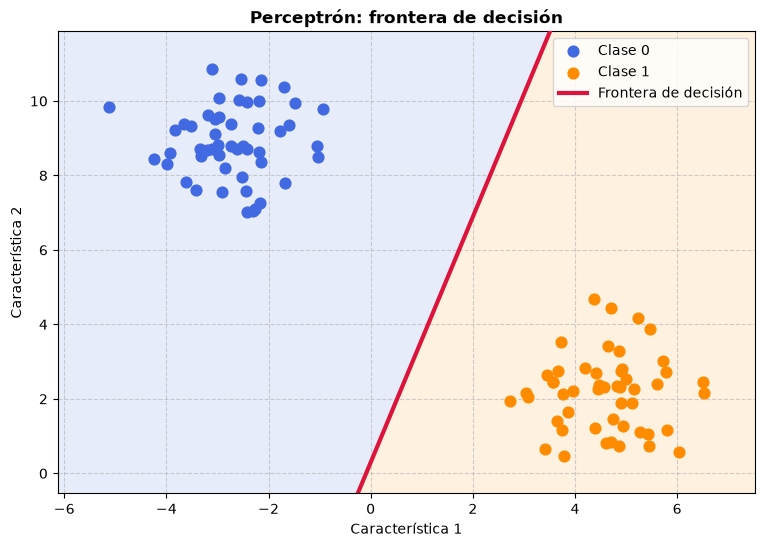

In [5]:
plt.figure(figsize=(9, 6))

# Fondo de color según la clase que predice el modelo
x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
rej_x1, rej_x2 = np.meshgrid(np.arange(x1_min, x1_max, 0.05), np.arange(x2_min, x2_max, 0.05))
zonas = clasificador.predict(np.c_[rej_x1.ravel(), rej_x2.ravel()]).reshape(rej_x1.shape)
plt.contourf(rej_x1, rej_x2, zonas, levels=[-0.5, 0.5, 1.5], colors=['royalblue', 'darkorange'], alpha=0.12)

# Puntos de cada clase
plt.scatter(X[Y == 0][:, 0], X[Y == 0][:, 1], color='royalblue', s=60, label='Clase 0', zorder=5)
plt.scatter(X[Y == 1][:, 0], X[Y == 1][:, 1], color='darkorange', s=60, label='Clase 1', zorder=5)

# Frontera de decisión: donde w1*x1 + w2*x2 + b = 0, se despeja x2
x1_recta = np.linspace(x1_min, x1_max, 100)
x2_recta = -(w1 * x1_recta + b) / w2
plt.plot(x1_recta, x2_recta, color='crimson', linewidth=3, label='Frontera de decisión', zorder=4)

plt.title('Perceptrón: frontera de decisión', fontweight='bold')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Explicación de los resultados

La recta que aprendió el perceptrón es **11.2337·x1 - 3.4070·x2 + 1.0000 = 0**.
Los puntos de un lado de la recta son clase 0 y los del otro lado, clase 1.

Necesitó 7 épocas y clasificó bien el 100% de los puntos, porque los dos grupos se pueden
separar con una línea recta. Si los grupos estuvieran mezclados, un solo perceptrón no lograría separarlos.

La función escalón dio las mismas predicciones que el modelo, lo que confirma cómo funciona por dentro.

## 2. Funciones de activación

Una función de activación transforma el resultado de la suma ponderada de una neurona. Su salida es el resultado del modelo o la entrada de la siguiente capa.

El perceptrón anterior usa la función escalón. Hay otras muy usadas:

| Función | Salida | Uso común |
|---|---|---|
| Escalón | 0 o 1 | Perceptrón original |
| Sigmoide | entre 0 y 1 | Probabilidades, clasificación binaria |
| Tanh | entre -1 y 1 | Capas ocultas |
| ReLU | 0 si es negativo, igual al valor si es positivo | Capas ocultas de redes profundas |

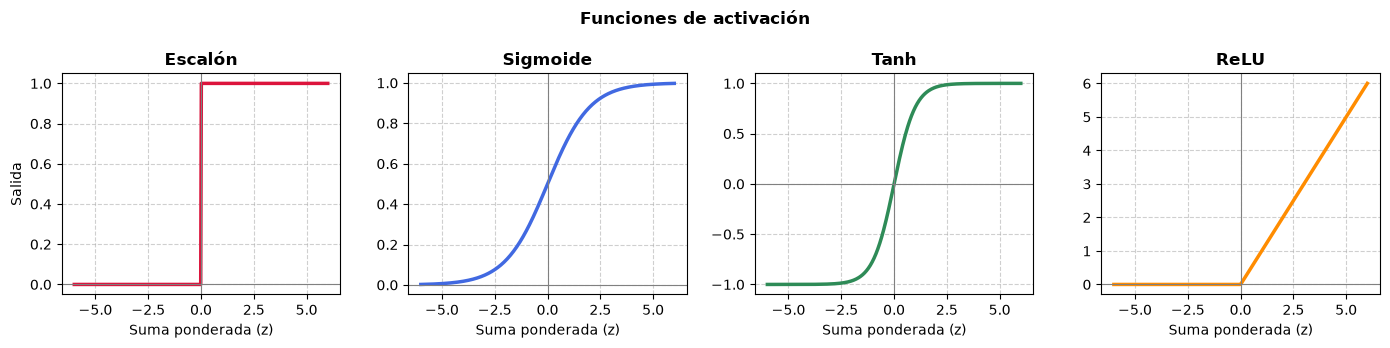

In [6]:
# Evalúa las cuatro funciones sobre el mismo rango de valores
z = np.linspace(-6, 6, 400)

activaciones = [
    ('Escalón', (z >= 0).astype(float), 'crimson'),
    ('Sigmoide', 1 / (1 + np.exp(-z)), 'royalblue'),
    ('Tanh', np.tanh(z), 'seagreen'),
    ('ReLU', np.maximum(0, z), 'darkorange'),
]

figura, ejes = plt.subplots(1, 4, figsize=(14, 3.5))
for eje, (nombre, valores, color) in zip(ejes, activaciones):
    eje.plot(z, valores, color=color, linewidth=2.5)
    eje.axhline(0, color='gray', linewidth=0.8)
    eje.axvline(0, color='gray', linewidth=0.8)
    eje.set_title(nombre, fontweight='bold')
    eje.set_xlabel('Suma ponderada (z)')
    eje.grid(True, linestyle='--', alpha=0.6)

ejes[0].set_ylabel('Salida')
figura.suptitle('Funciones de activación', fontweight='bold')
figura.tight_layout()
plt.show()

### Importancia de las funciones de activación

Las funciones **no lineales** (sigmoide, tanh, ReLU) permiten que una red neuronal aprenda relaciones complejas. Sin ellas, aunque se agreguen muchas capas, la red seguiría siendo equivalente a un solo modelo lineal y no podría separar datos que no se separan con una recta.

## 3. Neurona lineal visto en clase

Este ejemplo convierte grados Celsius a Fahrenheit con una neurona lineal (`SGDRegressor`) entrenada con descenso de gradiente estocástico. La fórmula real es **F = 1.8 · C + 32**, así que se puede comprobar si la neurona la descubre.

Antes de entrenar se **escalan** los datos con `StandardScaler` para que el descenso de gradiente converja bien. Después hay que deshacer el escalado para obtener el peso y el sesgo en grados Celsius.

In [7]:
import numpy as np
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

# 1. Datos: Celsius y su Fahrenheit exacto
X_celsius = np.array([-40, -20, 0, 10, 20, 30, 40, 100]).reshape(-1, 1)
y_fahrenheit = X_celsius.ravel() * 1.8 + 32

# 2. Escala los datos (media 0, desviación 1)
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_celsius)

# 3. Entrena la neurona lineal
regresor = SGDRegressor(max_iter=1000, tol=1e-3, learning_rate='invscaling', eta0=0.01, random_state=42)
regresor.fit(X_escalado, y_fahrenheit)

# 4. Predice con temperaturas nuevas
prueba_celsius = np.array([15, 25, 37]).reshape(-1, 1)
predicciones = regresor.predict(scaler.transform(prueba_celsius))

for c, f_pred in zip(prueba_celsius.ravel(), predicciones):
    print(f"{c}°C -> neurona: {f_pred:.2f}°F | real: {c * 1.8 + 32:.2f}°F")

15°C -> neurona: 58.82°F | real: 59.00°F
25°C -> neurona: 76.76°F | real: 77.00°F
37°C -> neurona: 98.30°F | real: 98.60°F


In [9]:
# Peso y sesgo en el espacio escalado
w_escalado = regresor.coef_[0]
b_escalado = regresor.intercept_[0]
print(f"Escalado -> peso: {w_escalado:.4f}, sesgo: {b_escalado:.4f}")

# Deshace el escalado: x_escalado = (x - media) / desviación
media = scaler.mean_[0]
desviacion = scaler.scale_[0]
w_original = w_escalado / desviacion
b_original = b_escalado - (w_escalado * media / desviacion)

print(f"Original -> peso: {w_original:.4f} (ideal 1.8), sesgo: {b_original:.4f} (ideal 32)")
print(f"Ecuación aprendida: F = {w_original:.2f} * C + {b_original:.2f}")

Escalado -> peso: 71.0714, sesgo: 63.3055
Original -> peso: 1.7944 (ideal 1.8), sesgo: 31.9036 (ideal 32)
Ecuación aprendida: F = 1.79 * C + 31.90


### Resultados obtenidos

La neurona aprendió **F = 1.79 · C + 31.90**, muy cercana a la fórmula real **F = 1.8 · C + 32**, por lo que sus
predicciones son bastante aproximadas. La diferencia pequeña se debe a que el descenso de gradiente estocástico se
detiene cuando el error ya es muy bajo, sin llegar al valor exacto.